# BRFSS 2015–2023 — bộ dữ liệu lớn (khoảng 3,9 triệu dòng)

Mở rộng notebook 07 (BRFSS 2021–2023, 683 nghìn dòng train) sang **9 năm BRFSS 2015–2023** để xem thêm dữ liệu cũ có giúp mô hình dự đoán trạng thái "từng được báo mắc đái tháo đường" hay không.

**Phép chia theo thời gian (khác notebook 07).** Train 2015–2021, validation 2022, test 2023. Notebook 07 train/validation là chia ngẫu nhiên 80/20 của 2021–2022 (validation cùng năm với train), còn ở đây validation là một năm *tương lai* so với train. **Test 2023 giống hệt notebook 07** (cùng các dòng, cùng luật nhãn) để so sánh công bằng; nhưng validation khác nên ngưỡng và việc chọn mô hình cũng khác.

**Hài hoà biến.** BRFSS đổi tên/mã biến qua các năm. Bảng ánh xạ biến × năm nằm ở phần đọc dữ liệu. 20 biến của notebook 07 được giữ nguyên ý nghĩa; hai biến tăng huyết áp/cholesterol (chỉ có năm lẻ) bị bỏ. Chỉ khác 07 ở biến thu nhập: `_INCOMG` (5 mức, 2015–2020) và `_INCOMG1` (7 mức, 2021+) được gộp về 5 mức chung.

Nguồn dữ liệu: CDC BRFSS, https://www.cdc.gov/brfss/annual_data/annual_data.htm (tài liệu của chính phủ Hoa Kỳ, phạm vi công cộng). Codebook từng năm:
- 2015: https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf
- 2016: https://www.cdc.gov/brfss/annual_data/2016/pdf/codebook16_llcp.pdf
- 2017: https://www.cdc.gov/brfss/annual_data/2017/pdf/codebook17_llcp-v2-508.pdf
- 2018: https://www.cdc.gov/brfss/annual_data/2018/pdf/codebook18_llcp-v2-508.pdf
- 2019: https://www.cdc.gov/brfss/annual_data/2019/pdf/codebook19_llcp-v2-508.HTML
- 2020: https://www.cdc.gov/brfss/annual_data/2020/pdf/codebook20_llcp-v2-508.pdf
- 2021: https://www.cdc.gov/brfss/annual_data/2021/pdf/codebook21_llcp-v2-508.pdf
- 2022: https://www.cdc.gov/brfss/annual_data/2022/zip/codebook22_llcp-v2-508.zip
- 2023: https://www.cdc.gov/brfss/annual_data/2023/zip/codebook23_llcp-v2-508.zip

Giới hạn như notebook 07: tự khai, cắt ngang, nhân quả ngược với bệnh kèm, không dùng survey weight, dữ liệu Hoa Kỳ, chỉ dùng học thuật. Test 2023 đã được xem trong các lần chạy trước.

## 1. Thiết lập
Chọn dữ liệu, cấu hình và đường dẫn. Mỗi lần chạy tạo một thư mục mới trong `artifacts/notebook_runs/`.

In [1]:
EXPERIMENT = 'brfss_2015_2023'
MODEL_TYPE = 'MLP'
PURPOSE = 'BRFSS 2015–2023: train 2015–2021, validation 2022, test 2023; 20 biến hài hoà qua 9 năm; nhãn tự khai từng được báo mắc ĐTĐ; không dùng survey weight.'
import os, json, hashlib, random, sys, platform
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, brier_score_loss)
import torch
from torch import nn
import joblib
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docker-compose.yml').exists()), None)
if ROOT is None: raise RuntimeError('Chạy notebook trong thư mục dự án.')
SMOKE = os.getenv('NOTEBOOK_SMOKE') == '1'  # Chỉ dùng cho kiểm thử kỹ thuật, không báo cáo kết quả.
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.set_num_threads(1)
run_stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
RUN_DIR = (Path('/tmp/duongan_notebook_smoke') if SMOKE else ROOT/'artifacts/notebook_runs') / EXPERIMENT / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print('Project:', ROOT, '| kết quả:', RUN_DIR, '| kiểm thử nhanh:', SMOKE)

Project: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project | kết quả: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss_2015_2023/20261112T132422_619456Z | kiểm thử nhanh: False


## 2. Đọc và biểu diễn dữ liệu
Đọc dữ liệu gốc và kiểm tra số dòng, cột. Các biểu đồ phân tích chi tiết ở mục 4 chỉ dùng tập train.

In [2]:
import pyreadstat, time
NOTEBOOK_T0 = time.perf_counter()
features = ['_BMI5', '_AGEG5YR', 'SEXVAR', '_SMOKER3', '_TOTINDA', 'GENHLTH', '_PHYS14D', '_MENT14D', 'DIFFWALK', 'CVDSTRK3', '_MICHD', 'CHCKDNY2', 'CHCCOPD3', 'ADDEPEV3', 'HEAVY_DRINK', 'HLTHPLAN', 'MEDCOST1', 'CHECKUP1', '_EDUCAG', 'INCOMG5']
numeric, categorical = ['_BMI5'], [c for c in features if c != '_BMI5']
FEATURE_DESCRIPTIONS = {'_BMI5': 'BMI (kg/m²)', '_AGEG5YR': 'Nhóm tuổi 5 năm (1=18–24 … 13=80+)', 'SEXVAR': 'Giới (1 nam, 2 nữ)', '_SMOKER3': 'Hút thuốc (1–2 hiện tại, 3 đã bỏ, 4 chưa từng)', '_TOTINDA': 'Vận động ngoài công việc 30 ngày qua (1 có, 2 không)', 'GENHLTH': 'Tự đánh giá sức khỏe chung (1 rất tốt … 5 kém)', '_PHYS14D': 'Số ngày sức khỏe thể chất kém (1: 0, 2: 1–13, 3: 14+); 2015 suy ra từ PHYSHLTH', '_MENT14D': 'Số ngày sức khỏe tinh thần kém (1: 0, 2: 1–13, 3: 14+); 2015 suy ra từ MENTHLTH', 'DIFFWALK': 'Khó khăn đi bộ/leo cầu thang (1 có, 2 không)', 'CVDSTRK3': 'Từng được báo đột quỵ (1 có, 2 không)', '_MICHD': 'Từng bệnh mạch vành/nhồi máu (1 có, 2 không)', 'CHCKDNY2': 'Từng được báo bệnh thận (1 có, 2 không)', 'CHCCOPD3': 'Từng được báo COPD (1 có, 2 không)', 'ADDEPEV3': 'Từng được báo trầm cảm (1 có, 2 không)', 'HEAVY_DRINK': 'Uống rượu nhiều (1 không, 2 có); 2021 _RFDRHV7, 2022–23 _RFDRHV8', 'HLTHPLAN': 'Có bảo hiểm/độ bao phủ y tế (1 có, 2 không); 2023 theo định nghĩa _HLTHPL1 (PRIMINS1)', 'MEDCOST1': 'Không đi khám được vì chi phí (1 có, 2 không)', 'CHECKUP1': 'Lần khám tổng quát gần nhất (1 <1 năm … 4 ≥5 năm, 8 chưa bao giờ)', '_EDUCAG': 'Học vấn (1–4)', 'INCOMG5': 'Nhóm thu nhập gộp 5 mức (1 <15k USD … 5 ≥50k USD)'}
YEARS = list(range(2015, 2024))
TRAIN_YEARS, VAL_YEAR, TEST_YEAR = list(range(2015, 2022)), 2022, 2023
# Ánh xạ biến hài hoà -> cột nguồn trong XPT từng năm (đã đối chiếu codebook CDC + nhãn biến trong file XPT).
SPANS = {'_BMI5': [((2015, 2023), '_BMI5')], '_AGEG5YR': [((2015, 2023), '_AGEG5YR')], 'SEXVAR': [((2015, 2017), 'SEX'), ((2018, 2018), 'SEX1'), ((2019, 2023), 'SEXVAR')], '_SMOKER3': [((2015, 2023), '_SMOKER3')], '_TOTINDA': [((2015, 2023), '_TOTINDA')], 'GENHLTH': [((2015, 2023), 'GENHLTH')], '_PHYS14D': [((2015, 2015), None), ((2016, 2023), '_PHYS14D')], '_MENT14D': [((2015, 2015), None), ((2016, 2023), '_MENT14D')], 'DIFFWALK': [((2015, 2023), 'DIFFWALK')], 'CVDSTRK3': [((2015, 2023), 'CVDSTRK3')], '_MICHD': [((2015, 2023), '_MICHD')], 'CHCKDNY2': [((2015, 2017), 'CHCKIDNY'), ((2018, 2018), 'CHCKDNY1'), ((2019, 2023), 'CHCKDNY2')], 'CHCCOPD3': [((2015, 2018), 'CHCCOPD1'), ((2019, 2020), 'CHCCOPD2'), ((2021, 2023), 'CHCCOPD3')], 'ADDEPEV3': [((2015, 2018), 'ADDEPEV2'), ((2019, 2023), 'ADDEPEV3')], 'HEAVY_DRINK': [((2015, 2017), '_RFDRHV5'), ((2018, 2018), '_RFDRHV6'), ((2019, 2021), '_RFDRHV7'), ((2022, 2023), '_RFDRHV8')], 'HLTHPLAN': [((2015, 2020), 'HLTHPLN1'), ((2021, 2022), '_HLTHPLN'), ((2023, 2023), '_HLTHPL1')], 'MEDCOST1': [((2015, 2020), 'MEDCOST'), ((2021, 2023), 'MEDCOST1')], 'CHECKUP1': [((2015, 2023), 'CHECKUP1')], '_EDUCAG': [((2015, 2023), '_EDUCAG')], 'INCOMG5': [((2015, 2020), '_INCOMG'), ((2021, 2023), '_INCOMG1')]}
COLUMN_MAP = {h: {y: src for (a, b), src in spans for y in range(a, b + 1)} for h, spans in SPANS.items()}
assert all(set(m) == set(YEARS) for m in COLUMN_MAP.values()), 'Bảng ánh xạ phải phủ đủ 9 năm'
LABEL_SOURCE = {y: ('DIABETE3' if y <= 2018 else 'DIABETE4') for y in YEARS}
DROPPED = {'_RFHYPE5/_RFHYPE6 (tăng huyết áp)': 'chỉ có 2015, 2017, 2019, 2021, 2023', '_RFCHOL1/_RFCHOL2/_RFCHOL3 (cholesterol cao)': 'chỉ có 2017, 2019, 2021, 2023'}
EXTRA_REPORT = {'variant': 'C_all_years_2015_2023_20_features', 'comparison_baseline': 'notebook 07 (cùng test 2023, validation khác)',
                'train_years': TRAIN_YEARS, 'validation_year': VAL_YEAR, 'test_year': TEST_YEAR,
                'column_map': {h: {str(y): s for y, s in m.items()} for h, m in COLUMN_MAP.items()},
                'label_source': {str(y): s for y, s in LABEL_SOURCE.items()}, 'dropped_variables': DROPPED,
                'codebooks': {'2015': 'https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf', '2016': 'https://www.cdc.gov/brfss/annual_data/2016/pdf/codebook16_llcp.pdf', '2017': 'https://www.cdc.gov/brfss/annual_data/2017/pdf/codebook17_llcp-v2-508.pdf', '2018': 'https://www.cdc.gov/brfss/annual_data/2018/pdf/codebook18_llcp-v2-508.pdf', '2019': 'https://www.cdc.gov/brfss/annual_data/2019/pdf/codebook19_llcp-v2-508.HTML', '2020': 'https://www.cdc.gov/brfss/annual_data/2020/pdf/codebook20_llcp-v2-508.pdf', '2021': 'https://www.cdc.gov/brfss/annual_data/2021/pdf/codebook21_llcp-v2-508.pdf', '2022': 'https://www.cdc.gov/brfss/annual_data/2022/zip/codebook22_llcp-v2-508.zip', '2023': 'https://www.cdc.gov/brfss/annual_data/2023/zip/codebook23_llcp-v2-508.zip'}}
display_map = pd.DataFrame({h: {y: (s if s else 'suy ra (PHYSHLTH/MENTHLTH)') for y, s in m.items()} for h, m in COLUMN_MAP.items()}).T
display_map.loc['(nhãn) DIABETE'] = [LABEL_SOURCE[y] for y in YEARS]
print('Bảng ánh xạ biến hài hoà × cột nguồn trong XPT từng năm:'); print(display_map.to_string())
print('\nBiến bị bỏ vì không có ở mọi năm:', DROPPED)
source_paths = [ROOT/f'data/raw/LLCP{year}.XPT' for year in YEARS]
def days_level(days):
    # Suy ra _PHYS14D/_MENT14D như CDC: 88 = 0 ngày -> 1; 1–13 -> 2; 14–30 -> 3; không biết/từ chối/trống -> 9.
    days = pd.to_numeric(days, errors='coerce')
    level = pd.Series(9, index=days.index, dtype='int8')
    level[days == 88] = 1; level[days.between(1, 13)] = 2; level[days.between(14, 30)] = 3
    return level
DERIVED_CHECK = {}
def read_survey(year):
    source = {h: m[year] for h, m in COLUMN_MAP.items()}
    need = sorted({c for c in source.values() if c} | {LABEL_SOURCE[year], 'PHYSHLTH', 'MENTHLTH'})
    kwargs = {'row_limit': 12000} if SMOKE else {}
    frame, _ = pyreadstat.read_xport(str(ROOT/f'data/raw/LLCP{year}.XPT'), usecols=need, encoding='latin1', **kwargs)
    missing = set(need) - set(frame.columns)
    if missing: raise ValueError(f'{year} thiếu cột {sorted(missing)}; kiểm tra codebook trước khi đổi bảng ánh xạ')
    out = pd.DataFrame({'DIABETE': frame[LABEL_SOURCE[year]]})
    for h, col in source.items():
        out[h] = frame[col] if col else days_level(frame['PHYSHLTH' if h == '_PHYS14D' else 'MENTHLTH'])
    # Kiểm chứng công thức suy ra: ở các năm có biến chính thức, so với _PHYS14D/_MENT14D của CDC.
    for h, raw_col in (('_PHYS14D', 'PHYSHLTH'), ('_MENT14D', 'MENTHLTH')):
        if source[h]:
            same = (days_level(frame[raw_col]).to_numpy() == pd.to_numeric(frame[source[h]], errors='coerce').fillna(9).to_numpy())
            DERIVED_CHECK.setdefault(h, {})[year] = float(same.mean())
    out['year'] = year
    return out
raw = {year: read_survey(year) for year in YEARS}
print('\nSố dòng gốc đọc từng năm:', {y: len(f) for y, f in raw.items()}, '| tổng', sum(len(f) for f in raw.values()))
print('Công thức suy ra _PHYS14D/_MENT14D khớp biến chính thức của CDC (tỷ lệ dòng trùng, theo năm):')
print(pd.DataFrame(DERIVED_CHECK).round(5).to_string())
EXTRA_REPORT['derived_check'] = {h: {str(y): v for y, v in d.items()} for h, d in DERIVED_CHECK.items()}

Bảng ánh xạ biến hài hoà × cột nguồn trong XPT từng năm:
                                      2015      2016      2017      2018      2019      2020      2021      2022      2023
_BMI5                                _BMI5     _BMI5     _BMI5     _BMI5     _BMI5     _BMI5     _BMI5     _BMI5     _BMI5
_AGEG5YR                          _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR  _AGEG5YR
SEXVAR                                 SEX       SEX       SEX      SEX1    SEXVAR    SEXVAR    SEXVAR    SEXVAR    SEXVAR
_SMOKER3                          _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3  _SMOKER3
_TOTINDA                          _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA  _TOTINDA
GENHLTH                            GENHLTH   GENHLTH   GENHLTH   GENHLTH   GENHLTH   GENHLTH   GENHLTH   GENHLTH   GENHLTH
_PHYS14D        suy ra (PHYSHLTH/MENTHLTH)  _PHYS14D  _PHYS14D  _PHYS14D  _PHYS14D


Số dòng gốc đọc từng năm: {2015: 441456, 2016: 486303, 2017: 450016, 2018: 437436, 2019: 418268, 2020: 401958, 2021: 438693, 2022: 445132, 2023: 433323} | tổng 3952585
Công thức suy ra _PHYS14D/_MENT14D khớp biến chính thức của CDC (tỷ lệ dòng trùng, theo năm):
      _PHYS14D  _MENT14D
2016       1.0       1.0
2017       1.0       1.0
2018       1.0       1.0
2019       1.0       1.0
2020       1.0       1.0
2021       1.0       1.0
2022       1.0       1.0
2023       1.0       1.0


## 3. Làm sạch, định nghĩa nhãn và chia tập
Loại nhãn không hợp lệ, kiểm soát dữ liệu thiếu và tách test. Các phép học tham số xử lý dữ liệu chỉ được fit sau khi chia tập.

In [3]:
codes = {'_AGEG5YR': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13], 'SEXVAR': [1, 2], '_SMOKER3': [1, 2, 3, 4], '_TOTINDA': [1, 2], 'GENHLTH': [1, 2, 3, 4, 5], '_PHYS14D': [1, 2, 3], '_MENT14D': [1, 2, 3], 'DIFFWALK': [1, 2], 'CVDSTRK3': [1, 2], '_MICHD': [1, 2], 'CHCKDNY2': [1, 2], 'CHCCOPD3': [1, 2], 'ADDEPEV3': [1, 2], 'HEAVY_DRINK': [1, 2], 'MEDCOST1': [1, 2], 'CHECKUP1': [1, 2, 3, 4, 8], '_EDUCAG': [1, 2, 3, 4], 'HLTHPLAN': [1, 2], 'INCOMG5': [1, 2, 3, 4, 5]}
def clean_survey(frame):
    # Nhãn: DIABETE = 1 (từng được báo mắc ĐTĐ) -> 1; 3 (không) -> 0. Loại 2 (chỉ khi mang thai), 4 (tiền ĐTĐ), 7/9 (không biết/từ chối), trống.
    df = frame[frame.DIABETE.isin([1, 3])].copy()
    df['class'] = df.DIABETE.map({1: 1, 3: 0}).astype('int8')
    df['_BMI5'] = (pd.to_numeric(df['_BMI5'], errors='coerce') / 100).where(lambda x: x.between(10, 100)).astype('float32')
    year = int(df['year'].iloc[0])
    if year >= 2021:  # _INCOMG1 7 mức -> 5 mức chung với _INCOMG: 50–<100k, 100–<200k, ≥200k đều thành "≥50k" (5)
        df['INCOMG5'] = pd.to_numeric(df['INCOMG5'], errors='coerce').replace({6: 5, 7: 5})
    for col, valid in codes.items():
        values = pd.to_numeric(df[col], errors='coerce')
        # Mã 7/9 (không biết/từ chối) và trống trở thành thiếu (NaN), được impute bằng giá trị hay gặp nhất của train.
        df[col] = values.where(values.isin(valid)).astype('float32')
    return df[features + ['class', 'year']].reset_index(drop=True)
frames = {year: clean_survey(frame) for year, frame in raw.items()}
del raw
print('Sau lọc nhãn theo năm:', {y: len(f) for y, f in frames.items()})
print('Tỷ lệ nhãn 1 theo năm:', {y: round(float(f['class'].mean()), 4) for y, f in frames.items()})
train = pd.concat([frames[y] for y in TRAIN_YEARS], ignore_index=True)
val, test = frames[VAL_YEAR].reset_index(drop=True), frames[TEST_YEAR].reset_index(drop=True)
del frames
EXTRA_REPORT['rows_after_label_filter_by_year'] = {str(y): int((train.year == y).sum()) for y in TRAIN_YEARS} | {str(VAL_YEAR): len(val), str(TEST_YEAR): len(test)}
EXTRA_REPORT['positive_rate_by_year'] = {str(y): float(train.loc[train.year == y, 'class'].mean()) for y in TRAIN_YEARS} | {str(VAL_YEAR): float(val['class'].mean()), str(TEST_YEAR): float(test['class'].mean())}
print(f'Train 2015–2021: {len(train):,} | validation 2022: {len(val):,} | test 2023: {len(test):,} | tổng {len(train)+len(val)+len(test):,}')
print('Bộ nhớ train (MB):', round(train.memory_usage(deep=True).sum() / 1e6, 1))

Sau lọc nhãn theo năm: {2015: 429360, 2016: 472937, 2017: 437704, 2018: 424460, 2019: 404492, 2020: 389158, 2021: 423958, 2022: 429880, 2023: 418492}
Tỷ lệ nhãn 1 theo năm: {2015: 0.1334, 2016: 0.1397, 2017: 0.1381, 2018: 0.143, 2019: 0.1419, 2020: 0.1339, 2021: 0.1359, 2022: 0.1423, 2023: 0.1429}
Train 2015–2021: 2,982,069 | validation 2022: 429,880 | test 2023: 418,492 | tổng 3,830,441
Bộ nhớ train (MB): 265.4


## 4. Biểu diễn và phân tích dữ liệu train
Kiểm tra phân bố nhãn, thiếu dữ liệu, thống kê, histogram theo nhãn và tương quan các biến số. Mẫu hiển thị có thể được giới hạn để vẽ nhanh; huấn luyện dùng toàn bộ tập train.

train: 2982069 mẫu; nhãn: {0: 2570506, 1: 411563}
validation: 429880 mẫu; nhãn: {0: 368722, 1: 61158}
test: 418492 mẫu; nhãn: {0: 358706, 1: 59786}

Thiếu dữ liệu trên train (%):


INCOMG5        18.36
_BMI5           8.79
HEAVY_DRINK     6.68
_SMOKER3        4.49
DIFFWALK        3.62
_TOTINDA        3.17
_PHYS14D        2.14
_MENT14D        1.73
_AGEG5YR        1.64
CHECKUP1        1.28
HLTHPLAN        0.93
_MICHD          0.87
ADDEPEV3        0.44
CHCCOPD3        0.44
_EDUCAG         0.41
CHCKDNY2        0.31
MEDCOST1        0.30
GENHLTH         0.25
CVDSTRK3        0.25
SEXVAR          0.05

Thống kê biến số trên train:


            _BMI5
count  2720092.00
mean        28.18
std          6.38
min         12.00
25%         23.85
50%         27.20
75%         31.24
max         99.95


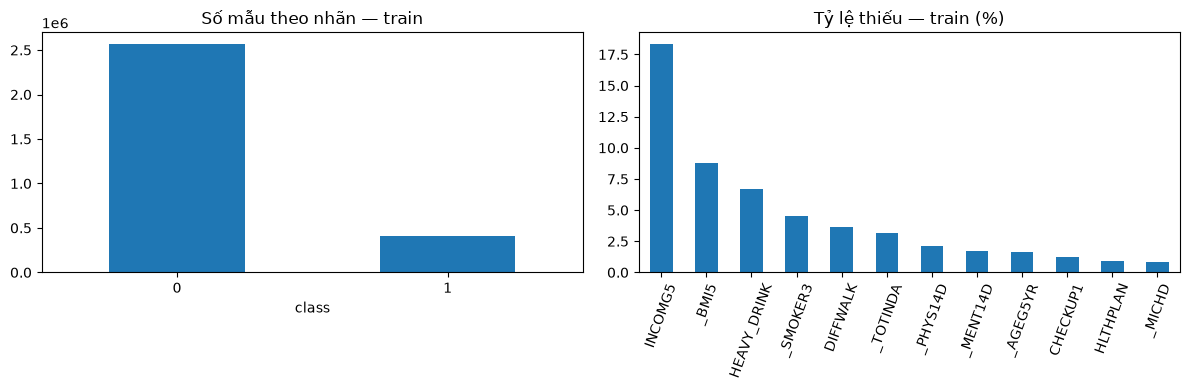

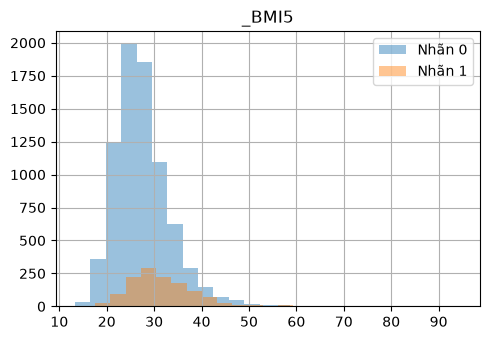

In [4]:
# Phân tích trên tập train để không dùng test quyết định đặc trưng.
for name, frame in [('train',train),('validation',val),('test',test)]:
    counts = frame['class'].value_counts().sort_index().to_dict()
    print(f'{name}: {len(frame)} mẫu; nhãn: {counts}')
    if frame['class'].nunique() != 2: raise ValueError(f'{name} cần đủ hai lớp')
print('\nThiếu dữ liệu trên train (%):')
print((train[features].isna().mean().sort_values(ascending=False)*100).round(2).to_string())
print('\nThống kê biến số trên train:')
print(train[numeric].describe().round(2).to_string())
fig,axes=plt.subplots(1,2,figsize=(12,4))
train['class'].value_counts().sort_index().plot.bar(ax=axes[0],title='Số mẫu theo nhãn — train',rot=0)
(train[features].isna().mean()*100).sort_values(ascending=False).head(12).plot.bar(ax=axes[1],title='Tỷ lệ thiếu — train (%)',rot=70)
plt.tight_layout(); plt.show()
# Số mẫu lớn chỉ lấy tối đa 10.000 điểm train cho biểu đồ, không thay đổi dữ liệu huấn luyện.
visual=train.sample(n=min(10000,len(train)),random_state=SEED)
plot_cols=numeric[:min(4,len(numeric))]
fig,axes=plt.subplots(1,len(plot_cols),figsize=(5*len(plot_cols),3.5),squeeze=False)
for ax,col in zip(axes[0],plot_cols):
    for label in (0,1):
        visual.loc[visual['class']==label,col].dropna().hist(ax=ax,bins=25,alpha=.45,label=f'Nhãn {label}')
    ax.set_title(col); ax.legend()
plt.tight_layout(); plt.show()
if len(numeric)>1:
    corr=visual[numeric].corr(numeric_only=True)
    fig,ax=plt.subplots(figsize=(max(6,len(corr)*.65),max(5,len(corr)*.65)))
    im=ax.imshow(corr,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(corr)),corr.columns,rotation=75,ha='right'); ax.set_yticks(range(len(corr)),corr.index)
    ax.set_title('Tương quan các biến số — train'); fig.colorbar(im,ax=ax); plt.tight_layout(); plt.show()

## 5. Tiền xử lý
Điền khuyết và chuẩn hóa trên train; biến phân loại one-hot. Áp dụng các phép biến đổi đã học lên validation/test.

In [5]:
def frame_x(frame): return frame[features]  # float32, thiếu = NaN; không sao chép sang object để tiết kiệm bộ nhớ
parts = [('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), numeric),
         ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'), OneHotEncoder(handle_unknown='ignore', dtype=np.float32)), categorical)]
preprocessor = ColumnTransformer(parts, sparse_threshold=0)
Xtr = preprocessor.fit_transform(frame_x(train)).astype('float32')
Xva = preprocessor.transform(frame_x(val)).astype('float32')
Xte = preprocessor.transform(frame_x(test)).astype('float32')
ytr, yva, yte = [f['class'].to_numpy(dtype='float32') for f in (train, val, test)]
print('Kích thước sau tiền xử lý (fit chỉ trên train):', Xtr.shape, Xva.shape, Xte.shape, '| Xtr MB:', round(Xtr.nbytes / 1e6))

Kích thước sau tiền xử lý (fit chỉ trên train): (2982069, 65) (429880, 65) (418492, 65) | Xtr MB: 775


## 6. Định nghĩa mô hình và baseline
Mạng nơ-ron so sánh với Dummy, Logistic Regression và HistGradientBoosting. CNN 1D trên dữ liệu bảng là giả định thực nghiệm về thứ tự cột.

In [6]:
# So sánh với baseline đơn giản và mô hình phi tuyến trên cùng dữ liệu.
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, roc_curve, precision_recall_curve
class Net(nn.Module):
    def __init__(self,n):
        super().__init__()
        if MODEL_TYPE=='MLP':
            self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,1))
        else:
            self.net=nn.Sequential(nn.Unflatten(1,(1,n)),nn.Conv1d(1,16,3,padding=1),nn.ReLU(),nn.Conv1d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool1d(2),nn.Flatten(),nn.Linear(32*(n//2),32),nn.ReLU(),nn.Dropout(.2),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(-1)
print('Kiến trúc ứng viên:'); print(Net(Xtr.shape[1]))
print('So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.')

Kiến trúc ứng viên:
Net(
  (net): Sequential(
    (0): Linear(in_features=65, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=1, bias=True)
  )
)
So sánh thêm: Dummy prior, Logistic Regression, HistGradientBoosting.


## 7. Huấn luyện và kiểm tra hội tụ
Tối đa 200 epoch, tối thiểu 40 epoch và dừng sớm nếu validation loss không cải thiện trong 25 epoch. Chạy ba seed khởi tạo; đồ thị hiển thị train/validation loss, epoch tốt nhất và số bước cập nhật. Seed chỉ đo độ nhạy khởi tạo, không thay thế kiểm định trên nhiều tập chia độc lập.

Training dummy


  dummy: 0.1 s


Training logistic_regression


  logistic_regression: 3.1 s


Training hist_gradient_boosting


  hist_gradient_boosting: 32.1 s


... (10 outputs left out)

  seed 44 epoch 10: val_loss=0.8892, 26 s


  seed 44 epoch 20: val_loss=0.8896, 58 s


  seed 44 epoch 30: val_loss=0.8898, 104 s


seed=44: epochs=40, best=15, updates=29160, val AUC=0.8244, early_stop=True, 145.5 s


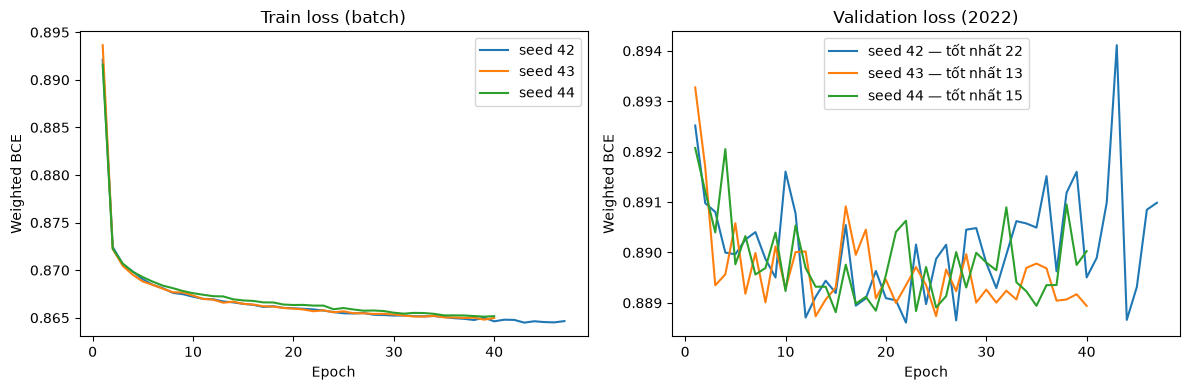

Dao động validation AUC giữa các seed: [0.8245, 0.8245, 0.8244]


In [7]:
# Cùng tập train/validation cho tất cả ứng viên. Ba seed chỉ thay đổi khởi tạo,
# không thay thế việc đánh giá trên nhiều phép chia dữ liệu độc lập.
from copy import deepcopy
MLP_TRAIN_MAX = None  # None = MLP học trên toàn bộ train; số nguyên = mẫu con phân tầng (LR/HGB luôn dùng toàn bộ train)
TRAINING_SECONDS = {}
candidates = {
    'dummy': DummyClassifier(strategy='prior'),
    'logistic_regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    'hist_gradient_boosting': HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5, max_leaf_nodes=15, class_weight='balanced', random_state=SEED),
}
for name, estimator in candidates.items():
    t0 = time.perf_counter(); print('Training', name, flush=True); estimator.fit(Xtr, ytr)
    TRAINING_SECONDS[name] = round(time.perf_counter() - t0, 1); print(f'  {name}: {TRAINING_SECONDS[name]} s', flush=True)

seeds = [42] if SMOKE else [42, 43, 44]
max_epochs = 2 if SMOKE else 200
min_epochs = 1 if SMOKE else 40
patience_limit = 2 if SMOKE else 25
batch_size = 4096
if MLP_TRAIN_MAX and len(ytr) > MLP_TRAIN_MAX:
    mlp_idx = np.sort(train_test_split(np.arange(len(ytr)), train_size=MLP_TRAIN_MAX, stratify=ytr, random_state=SEED)[0])
else:
    mlp_idx = np.arange(len(ytr))
xt = torch.from_numpy(Xtr[mlp_idx]) if len(mlp_idx) < len(ytr) else torch.from_numpy(Xtr)
yt = torch.from_numpy(ytr[mlp_idx]) if len(mlp_idx) < len(ytr) else torch.from_numpy(ytr)
xv, yv = torch.from_numpy(Xva), torch.from_numpy(yva)
print('MLP học trên', len(yt), 'dòng train')
pos_weight = torch.tensor([(len(yt) - float(yt.sum())) / float(yt.sum())], dtype=torch.float32)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
runs = []
for run_seed in seeds:
    t0 = time.perf_counter()
    torch.manual_seed(run_seed); random.seed(run_seed); np.random.seed(run_seed)
    model = Net(Xtr.shape[1]); optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    generator = torch.Generator().manual_seed(run_seed)
    best_loss = float('inf'); best_state = None; best_epoch = 0; patience = 0; history = []; updates = 0
    for epoch in range(1, max_epochs + 1):
        model.train(); total_loss = 0.0
        order = torch.randperm(len(yt), generator=generator)  # cắt lô trực tiếp từ tensor, nhanh hơn DataLoader nhiều lần
        for start in range(0, len(order), batch_size):
            ix = order[start:start + batch_size]
            x, y = xt[ix], yt[ix]
            optimizer.zero_grad(); loss = loss_fn(model(x), y); loss.backward(); optimizer.step()
            total_loss += float(loss.detach()) * len(y); updates += 1
        model.eval()
        with torch.no_grad(): val_loss = float(loss_fn(model(xv), yv))
        history.append({'epoch': epoch, 'train_loss': total_loss / len(yt), 'val_loss': val_loss})
        if val_loss < best_loss - 1e-4:
            best_loss = val_loss; best_epoch = epoch; best_state = deepcopy(model.state_dict()); patience = 0
        else: patience += 1
        if epoch >= min_epochs and patience >= patience_limit: break
        if epoch % 10 == 0: print(f'  seed {run_seed} epoch {epoch}: val_loss={val_loss:.4f}, {time.perf_counter() - t0:.0f} s', flush=True)
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad(): valid_scores = torch.sigmoid(model(xv)).numpy()
    run = {'seed': run_seed, 'model': model, 'best_epoch': best_epoch, 'epochs_run': len(history),
           'updates': updates, 'stopped_early': len(history) < max_epochs, 'history': history,
           'val_scores': valid_scores, 'val_auc': float(roc_auc_score(yva, valid_scores))}
    runs.append(run)
    TRAINING_SECONDS[f'neural_seed_{run_seed}'] = round(time.perf_counter() - t0, 1)
    print(f"seed={run_seed}: epochs={len(history)}, best={best_epoch}, updates={updates}, val AUC={run['val_auc']:.4f}, early_stop={run['stopped_early']}, {TRAINING_SECONDS[f'neural_seed_{run_seed}']} s", flush=True)
EXTRA_REPORT['training_seconds'] = TRAINING_SECONDS
EXTRA_REPORT['mlp_train_rows'] = int(len(yt)); EXTRA_REPORT['mlp_train_subsampled'] = bool(len(yt) < len(ytr))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for run in runs:
    curve = pd.DataFrame(run['history'])
    axes[0].plot(curve.epoch, curve.train_loss, label=f"seed {run['seed']}")
    axes[1].plot(curve.epoch, curve.val_loss, label=f"seed {run['seed']} — tốt nhất {run['best_epoch']}")
for ax, title in zip(axes, ['Train loss (batch)', 'Validation loss (2022)']): ax.set_title(title); ax.set_xlabel('Epoch'); ax.set_ylabel('Weighted BCE'); ax.legend()
plt.tight_layout(); plt.show()
print('Dao động validation AUC giữa các seed:', [round(r['val_auc'], 4) for r in runs])

## 8. So sánh và lựa chọn trên validation
Bảng so sánh ROC-AUC, PR-AUC, precision, recall, F1; chọn ứng viên theo ROC-AUC validation, sau đó chọn ngưỡng theo F1 validation. Test không tham gia lựa chọn.

Bảng validation (ngưỡng tham khảo 0.5):
                        roc_auc  pr_auc  precision  recall      f1
neural_seed_42           0.8245  0.4278     0.3027  0.8028  0.4396
neural_seed_43           0.8245  0.4278     0.3023  0.8043  0.4395
neural_seed_44           0.8244  0.4280     0.3030  0.8020  0.4398
hist_gradient_boosting   0.8233  0.4260     0.3058  0.7925  0.4413
logistic_regression      0.8188  0.4115     0.3107  0.7682  0.4424
dummy                    0.5000  0.1423     0.0000  0.0000  0.0000


Chọn theo validation ROC-AUC: neural_seed_42 | ngưỡng F1 trên validation: 0.65
 threshold  precision  recall     f1
      0.05     0.1636  0.9954 0.2810
      0.10     0.1838  0.9855 0.3098
      0.15     0.1999  0.9736 0.3316
      0.20     0.2133  0.9600 0.3490
      0.25     0.2264  0.9458 0.3653
      0.30     0.2395  0.9283 0.3808
      0.35     0.2530  0.9055 0.3955
      0.40     0.2677  0.8772 0.4102
      0.45     0.2846  0.8435 0.4256
      0.50     0.3027  0.8028 0.4396
      0.55     0.3228  0.7539 0.4520
      0.60     0.3468  0.6911 0.4619
      0.65     0.3761  0.6156 0.4669
      0.70     0.4095  0.5252 0.4602
      0.75     0.4485  0.4211 0.4344
      0.80     0.4985  0.2990 0.3738
      0.85     0.5649  0.1670 0.2578
      0.90     0.6535  0.0586 0.1076
      0.95     0.7799  0.0072 0.0144


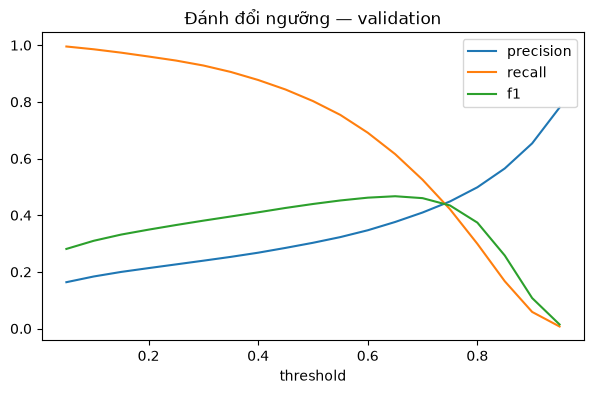

In [8]:
# So sánh validation theo nhiều chỉ số. AUC quyết định mô hình; ngưỡng F1 được chọn riêng trên validation.
val_scores={name:est.predict_proba(Xva)[:,1] for name,est in candidates.items()}
for run in runs: val_scores[f"neural_seed_{run['seed']}"]=run['val_scores']
def threshold_scores(y, scores, threshold):
    pred=(scores>=threshold).astype(int)
    return {'roc_auc':float(roc_auc_score(y,scores)),'pr_auc':float(average_precision_score(y,scores)),
            'precision':float(precision_score(y,pred,zero_division=0)),'recall':float(recall_score(y,pred,zero_division=0)),
            'f1':float(f1_score(y,pred,zero_division=0))}
validation_table=pd.DataFrame({name:threshold_scores(yva,s,.5) for name,s in val_scores.items()}).T.sort_values('roc_auc',ascending=False)
print('Bảng validation (ngưỡng tham khảo 0.5):'); print(validation_table.round(4).to_string())
# Nếu bằng AUC, ưu tiên baseline đơn giản theo thứ tự khai báo.
priority=list(val_scores)
selected=max(priority,key=lambda name:roc_auc_score(yva,val_scores[name]))
threshold_grid=np.round(np.linspace(.05,.95,19),2)
threshold_table=pd.DataFrame([{'threshold':float(t),**threshold_scores(yva,val_scores[selected],t)} for t in threshold_grid])
selected_threshold=float(threshold_table.loc[threshold_table.f1.idxmax(),'threshold'])
print('Chọn theo validation ROC-AUC:',selected,'| ngưỡng F1 trên validation:',selected_threshold)
print(threshold_table[['threshold','precision','recall','f1']].round(4).to_string(index=False))
threshold_table.plot(x='threshold',y=['precision','recall','f1'],title='Đánh đổi ngưỡng — validation',figsize=(7,4));plt.show()
# Ngưỡng F1 là lựa chọn thực nghiệm, không phải ngưỡng lâm sàng.

## 9. Đánh giá test của mô hình đã chọn
Bảng chỉ số, báo cáo phân loại, ROC, Precision–Recall, ma trận nhầm lẫn và khoảng bootstrap phân tầng. Đây là đánh giá học thuật không trọng số; tập test đã từng được sử dụng trong các lần chạy trước và không còn hoàn toàn độc lập.

Kết quả test CHỈ của ứng viên được chọn:
{
  "roc_auc": 0.821364991540905,
  "pr_auc": 0.4246291535962306,
  "precision": 0.3686902423704649,
  "recall": 0.618539457398053,
  "f1": 0.4619987881589386,
  "accuracy": 0.794196782734198,
  "brier": 0.18484532833099365,
  "confusion_matrix": [
    [
      295385,
      63321
    ],
    [
      22806,
      36980
    ]
  ]
}
Báo cáo phân loại:
              precision    recall  f1-score   support

         0.0       0.93      0.82      0.87    358706
         1.0       0.37      0.62      0.46     59786

    accuracy                           0.79    418492
   macro avg       0.65      0.72      0.67    418492
weighted avg       0.85      0.79      0.81    418492



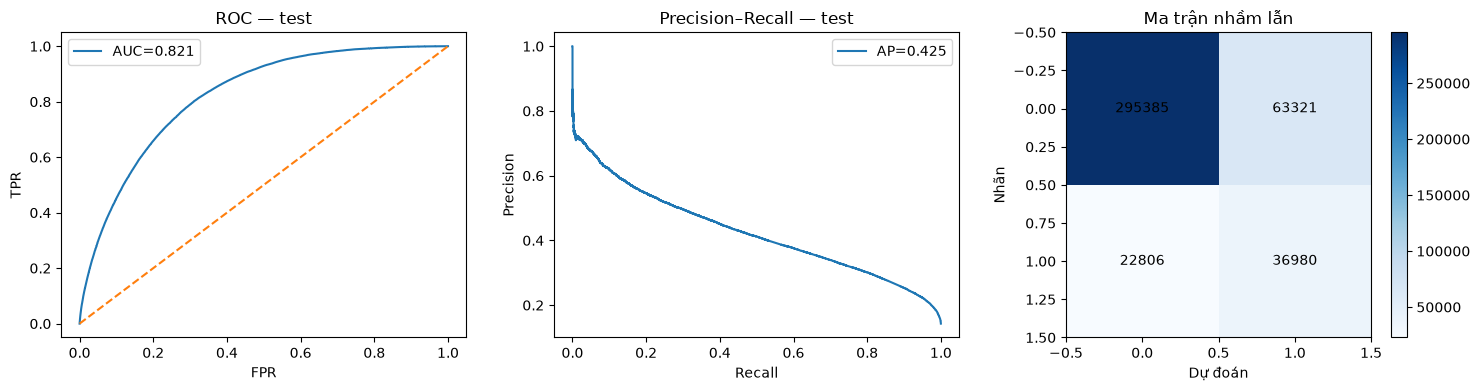

Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát): [0.8195370895726809, 0.8228072589313233]
Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.


In [9]:
if selected.startswith('neural_seed_'):
    best_run=next(r for r in runs if selected==f"neural_seed_{r['seed']}")
    best_run['model'].eval()
    with torch.no_grad(): test_scores=torch.sigmoid(best_run['model'](torch.tensor(Xte))).numpy()
else: test_scores=candidates[selected].predict_proba(Xte)[:,1]
pred=(test_scores>=selected_threshold).astype(int)
test_metrics={**threshold_scores(yte,test_scores,selected_threshold),
    'accuracy':float(accuracy_score(yte,pred)),'brier':float(brier_score_loss(yte,test_scores)),
    'confusion_matrix':confusion_matrix(yte,pred,labels=[0,1]).tolist()}
print('Kết quả test CHỈ của ứng viên được chọn:'); print(json.dumps(test_metrics,indent=2))
print('Báo cáo phân loại:');print(classification_report(yte,pred,zero_division=0))
fpr,tpr,_=roc_curve(yte,test_scores); prec,rec,_=precision_recall_curve(yte,test_scores)
fig,axes=plt.subplots(1,3,figsize=(15,4))
axes[0].plot(fpr,tpr,label=f"AUC={test_metrics['roc_auc']:.3f}");axes[0].plot([0,1],[0,1],'--');axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC — test');axes[0].legend()
axes[1].plot(rec,prec,label=f"AP={test_metrics['pr_auc']:.3f}");axes[1].set(xlabel='Recall',ylabel='Precision',title='Precision–Recall — test');axes[1].legend()
cm=np.array(test_metrics['confusion_matrix']); im=axes[2].imshow(cm,cmap='Blues'); axes[2].set(xlabel='Dự đoán',ylabel='Nhãn',title='Ma trận nhầm lẫn')
for (i,j),value in np.ndenumerate(cm): axes[2].text(j,i,str(value),ha='center',va='center')
fig.colorbar(im,ax=axes[2]);plt.tight_layout();plt.show()
# Bootstrap phân tầng, cố định số lượng mỗi lớp: khoảng mô tả có điều kiện theo mẫu test.
rng=np.random.default_rng(SEED); neg=np.flatnonzero(yte==0); pos=np.flatnonzero(yte==1)
bootstrap=[]
for _ in range(10 if SMOKE else 100):
    ix=np.concatenate([rng.choice(neg,len(neg),replace=True),rng.choice(pos,len(pos),replace=True)])
    bootstrap.append(roc_auc_score(yte[ix],test_scores[ix]))
auc_ci=np.quantile(bootstrap,[.025,.975]).tolist()
print('Khoảng bootstrap phân tầng 95% cho ROC-AUC (không tính thiết kế khảo sát):',auc_ci)
print('Lưu ý: dữ liệu test đã từng được xem trong các lần chạy trước; đây không còn là kiểm định cuối hoàn toàn độc lập.')

## 9b. Độ quan trọng đặc trưng
Mô hình đã chọn dựa vào biến nào nhiều nhất? Đo trên validation, không dùng test.

ROC-AUC gốc trên mẫu validation: 0.8253
_AGEG5YR       0.0793
GENHLTH        0.0534
_BMI5          0.0364
CHECKUP1       0.0177
_MICHD         0.0055
CHCKDNY2       0.0042
SEXVAR         0.0033
HEAVY_DRINK    0.0027
DIFFWALK       0.0020
_EDUCAG        0.0018
INCOMG5        0.0018
CVDSTRK3       0.0012
_TOTINDA       0.0010
ADDEPEV3       0.0005
_PHYS14D       0.0004
_SMOKER3       0.0004
_MENT14D       0.0004
MEDCOST1       0.0000
HLTHPLAN       0.0000
CHCCOPD3      -0.0000


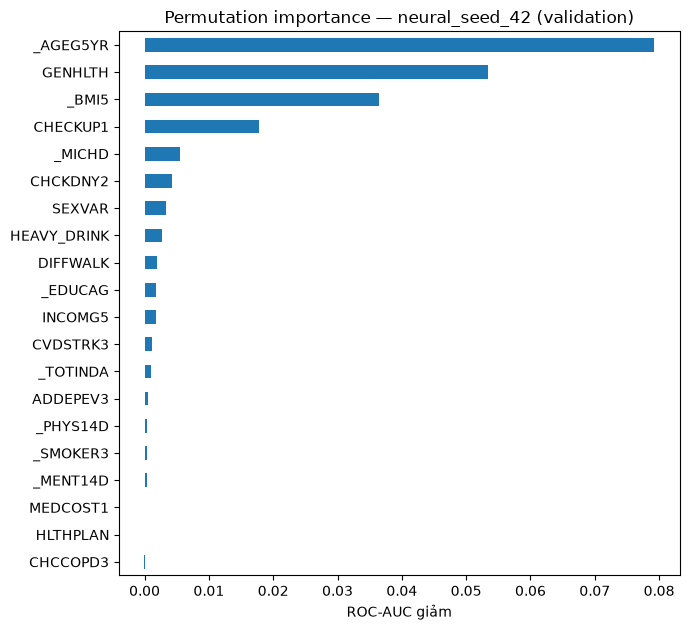

In [10]:
# Độ quan trọng đặc trưng (permutation importance) trên VALIDATION cho mô hình đã chọn.
# Xáo trộn từng cột gốc rồi đo ROC-AUC giảm bao nhiêu: giảm càng nhiều, mô hình càng dựa vào biến đó.
# Đây là mức độ mô hình sử dụng biến, KHÔNG phải quan hệ nhân quả.
def score_frame(frame):
    X = preprocessor.transform(frame_x(frame)).astype('float32')
    if selected.startswith('neural_seed_'):
        with torch.no_grad(): return torch.sigmoid(best_run['model'](torch.tensor(X))).numpy()
    return candidates[selected].predict_proba(X)[:, 1]
if selected.startswith('neural_seed_'):
    best_run = next(r for r in runs if selected == f"neural_seed_{r['seed']}")
sample = val.sample(n=min(20000, len(val)), random_state=SEED)
y_sample = sample['class'].to_numpy()
base_auc = roc_auc_score(y_sample, score_frame(sample))
rng_imp = np.random.default_rng(SEED)
importance = {}
for col in features:
    drops = []
    for _ in range(1 if SMOKE else 3):
        shuffled = sample.copy()
        shuffled[col] = rng_imp.permutation(shuffled[col].to_numpy())
        drops.append(base_auc - roc_auc_score(y_sample, score_frame(shuffled)))
    importance[col] = float(np.mean(drops))
importance = dict(sorted(importance.items(), key=lambda kv: kv[1], reverse=True))
print(f'ROC-AUC gốc trên mẫu validation: {base_auc:.4f}')
print(pd.Series(importance, name='AUC giảm khi xáo trộn').round(4).to_string())
pd.Series(importance).iloc[::-1].plot.barh(figsize=(7, max(3, len(features) * .32)), title=f'Permutation importance — {selected} (validation)')
plt.xlabel('ROC-AUC giảm'); plt.tight_layout(); plt.show()

## 9c. Hiệu năng theo từng năm
Mô hình đã chọn, ngưỡng cố định từ validation. Các năm train là trong mẫu nên lạc quan; chỉ validation 2022 và test 2023 là ngoài mẫu.

 năm                     vai trò      n  tỷ lệ dương  roc_auc  pr_auc  precision  recall     f1
2015 train (trong mẫu, lạc quan) 429360       0.1334   0.8328  0.4284     0.3670  0.6258 0.4626
2016 train (trong mẫu, lạc quan) 472937       0.1397   0.8300  0.4362     0.3737  0.6311 0.4694
2017 train (trong mẫu, lạc quan) 437704       0.1381   0.8320  0.4349     0.3721  0.6316 0.4683
2018 train (trong mẫu, lạc quan) 424460       0.1430   0.8319  0.4445     0.3772  0.6414 0.4750
2019 train (trong mẫu, lạc quan) 404492       0.1419   0.8305  0.4387     0.3717  0.6448 0.4716
2020 train (trong mẫu, lạc quan) 389158       0.1339   0.8315  0.4262     0.3747  0.5988 0.4609
2021 train (trong mẫu, lạc quan) 423958       0.1359   0.8283  0.4241     0.3703  0.6110 0.4612
2022                  validation 429880       0.1423   0.8245  0.4278     0.3761  0.6156 0.4669
2023                        test 418492       0.1429   0.8214  0.4246     0.3687  0.6185 0.4620


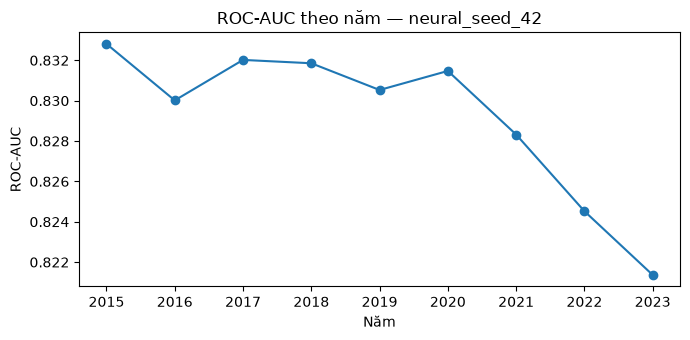

In [11]:
# Hiệu năng của mô hình ĐÃ CHỌN theo từng năm (ngưỡng đã chọn trên validation 2022).
def selected_scores(X):
    if selected.startswith('neural_seed_'):
        out = []
        with torch.no_grad():
            for s in range(0, len(X), 200000): out.append(torch.sigmoid(best_run['model'](torch.from_numpy(X[s:s + 200000]))).numpy())
        return np.concatenate(out)
    return candidates[selected].predict_proba(X)[:, 1]
train_scores_all = selected_scores(Xtr)
rows = []
for year in TRAIN_YEARS:
    mask = (train.year == year).to_numpy()
    rows.append({'năm': year, 'vai trò': 'train (trong mẫu, lạc quan)', 'n': int(mask.sum()), 'tỷ lệ dương': float(ytr[mask].mean()), **threshold_scores(ytr[mask], train_scores_all[mask], selected_threshold)})
rows.append({'năm': VAL_YEAR, 'vai trò': 'validation', 'n': len(yva), 'tỷ lệ dương': float(yva.mean()), **threshold_scores(yva, val_scores[selected], selected_threshold)})
rows.append({'năm': TEST_YEAR, 'vai trò': 'test', 'n': len(yte), 'tỷ lệ dương': float(yte.mean()), **threshold_scores(yte, test_scores, selected_threshold)})
per_year = pd.DataFrame(rows)
print(per_year.round(4).to_string(index=False))
del train_scores_all
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(per_year['năm'], per_year['roc_auc'], marker='o'); ax.set(title=f'ROC-AUC theo năm — {selected}', xlabel='Năm', ylabel='ROC-AUC'); plt.tight_layout(); plt.show()
EXTRA_REPORT['per_year_metrics_selected_model'] = per_year.to_dict(orient='records')

## 9d. Thêm năm cũ vào train có giúp không?
HistGradientBoosting cùng siêu tham số, chỉ đổi số năm train. Phân tích chẩn đoán, không dùng để chọn mô hình.

In [12]:
# Thêm năm cũ vào train có giúp không? HistGradientBoosting cùng siêu tham số, chỉ đổi cửa sổ năm train (kết thúc 2021),
# đánh giá trên validation 2022 và test 2023 (cùng ngưỡng 0,5 chỉ để tham khảo; so sánh bằng ROC-AUC/PR-AUC).
# Đây là phân tích chẩn đoán trên test đã được xem, KHÔNG dùng để chọn mô hình.
from sklearn.base import clone
windows = {'2021': [2021], '2020–2021': [2020, 2021], '2018–2021': list(range(2018, 2022)), '2015–2021': TRAIN_YEARS}
ablation_rows = []
for label, years in windows.items():
    if SMOKE and len(years) > 2: continue
    mask = train.year.isin(years).to_numpy(); t0 = time.perf_counter()
    prep = clone(preprocessor).fit(frame_x(train[mask]))
    est = HistGradientBoostingClassifier(max_iter=100 if not SMOKE else 5, max_leaf_nodes=15, class_weight='balanced', random_state=SEED)
    est.fit(prep.transform(frame_x(train[mask])).astype('float32'), ytr[mask])
    sv = est.predict_proba(prep.transform(frame_x(val)).astype('float32'))[:, 1]
    st = est.predict_proba(prep.transform(frame_x(test)).astype('float32'))[:, 1]
    ablation_rows.append({'cửa sổ train': label, 'n train': int(mask.sum()), 'val 2022 ROC-AUC': roc_auc_score(yva, sv), 'test 2023 ROC-AUC': roc_auc_score(yte, st),
                          'test 2023 PR-AUC': average_precision_score(yte, st), 'giây': round(time.perf_counter() - t0, 1)})
    print(ablation_rows[-1], flush=True)
ablation = pd.DataFrame(ablation_rows); print(ablation.round(4).to_string(index=False))
EXTRA_REPORT['train_window_ablation_hgb'] = ablation.to_dict(orient='records')

{'cửa sổ train': '2021', 'n train': 423958, 'val 2022 ROC-AUC': 0.8228790112531184, 'test 2023 ROC-AUC': 0.8202092149683488, 'test 2023 PR-AUC': 0.4233565711155972, 'giây': 9.6}


{'cửa sổ train': '2020–2021', 'n train': 813116, 'val 2022 ROC-AUC': 0.8231474656186744, 'test 2023 ROC-AUC': 0.8202602231312031, 'test 2023 PR-AUC': 0.42334209103140774, 'giây': 14.0}


{'cửa sổ train': '2018–2021', 'n train': 1642068, 'val 2022 ROC-AUC': 0.8234084313477408, 'test 2023 ROC-AUC': 0.820418197050664, 'test 2023 PR-AUC': 0.42377025999816453, 'giây': 32.9}


{'cửa sổ train': '2015–2021', 'n train': 2982069, 'val 2022 ROC-AUC': 0.823262391605968, 'test 2023 ROC-AUC': 0.8202037189450643, 'test 2023 PR-AUC': 0.4232583601463056, 'giây': 50.0}


cửa sổ train  n train  val 2022 ROC-AUC  test 2023 ROC-AUC  test 2023 PR-AUC  giây
        2021   423958            0.8229             0.8202            0.4234   9.6
   2020–2021   813116            0.8231             0.8203            0.4233  14.0
   2018–2021  1642068            0.8234             0.8204            0.4238  32.9
   2015–2021  2982069            0.8233             0.8202            0.4233  50.0


## 9e. So sánh với notebook 07
Cùng test 2023 (cùng số dòng và số ca dương). Khác nhau: dữ liệu train, cách chia validation, và biến thu nhập (5 mức thay vì 7).

In [13]:
# So sánh với notebook 07 trên CÙNG tập test 2023.
BASELINE_REPORT = ROOT/'artifacts/notebook_runs/brfss20/20261112T073448_850428Z/report.json'
base = json.loads(BASELINE_REPORT.read_text(encoding='utf-8'))
if not SMOKE:
    assert base['sizes']['test'] == len(test), f"Test khác nhau: 07={base['sizes']['test']}, 11={len(test)}"
    assert base['class_counts']['test'] == {str(k): int(v) for k, v in test['class'].value_counts().items()}, 'Phân bố nhãn test khác notebook 07'
t07 = base['test_selected_only']; ci07 = base['test_auc_bootstrap_stratified_95']
comparison = pd.DataFrame([
    {'notebook': '07 (2021–22 -> 2023)', 'train': base['sizes']['train'], 'validation': base['sizes']['validation'], 'cách chia val': 'ngẫu nhiên 20% của 2021–22', 'mô hình': base['selected_model'],
     'ROC-AUC': t07['roc_auc'], 'CI thấp': ci07[0], 'CI cao': ci07[1], 'PR-AUC': t07['pr_auc'], 'precision': t07['precision'], 'recall': t07['recall'], 'f1': t07['f1'], 'ngưỡng': base['selected_threshold']},
    {'notebook': '11 (2015–21 -> 2023)', 'train': len(train), 'validation': len(val), 'cách chia val': 'năm 2022', 'mô hình': selected,
     'ROC-AUC': test_metrics['roc_auc'], 'CI thấp': auc_ci[0], 'CI cao': auc_ci[1], 'PR-AUC': test_metrics['pr_auc'], 'precision': test_metrics['precision'], 'recall': test_metrics['recall'], 'f1': test_metrics['f1'], 'ngưỡng': selected_threshold}])
print(comparison.round(4).T.to_string())
print('\nThời gian train 07 (không ghi trong report; xem output notebook 07). Thời gian train 11 (giây):', TRAINING_SECONDS)
print('Khác biệt ROC-AUC (11 - 07):', round(test_metrics['roc_auc'] - t07['roc_auc'], 4))
EXTRA_REPORT['comparison_with_notebook_07'] = comparison.to_dict(orient='records')
EXTRA_REPORT['notebook_wall_seconds_before_save'] = round(time.perf_counter() - NOTEBOOK_T0, 1)

                                        0                     1
notebook             07 (2021–22 -> 2023)  11 (2015–21 -> 2023)
train                              683070               2982069
validation                         170768                429880
cách chia val  ngẫu nhiên 20% của 2021–22              năm 2022
mô hình                    neural_seed_42        neural_seed_42
ROC-AUC                            0.8217                0.8214
CI thấp                            0.8198                0.8195
CI cao                             0.8232                0.8228
PR-AUC                             0.4251                0.4246
precision                           0.365                0.3687
recall                             0.6316                0.6185
f1                                 0.4626                 0.462
ngưỡng                               0.65                  0.65

Thời gian train 07 (không ghi trong report; xem output notebook 07). Thời gian train 11 (giây): {'dummy

## 10. Lưu model, cấu hình và kết quả
Lưu cả ba baseline, ba seed mạng, đường loss, lựa chọn, ngưỡng, các chỉ số và hash. Không tự thay thế model website.

In [14]:
def file_sha256(path):
    digest=hashlib.sha256()
    with path.open('rb') as stream:
        for chunk in iter(lambda:stream.read(1024*1024),b''): digest.update(chunk)
    return digest.hexdigest()
hashes={str(p.relative_to(ROOT)):file_sha256(p) for p in source_paths}
run_info=[{k:r[k] for k in ['seed','best_epoch','epochs_run','updates','stopped_early','val_auc','history']} for r in runs]
report={'experiment':EXPERIMENT,'purpose':PURPOSE,'model_type':MODEL_TYPE,'smoke_test':SMOKE,
 'source_sha256':hashes,'features':features,'sizes':{'train':len(train),'validation':len(val),'test':len(test)},
 'class_counts':{name:{str(k):int(v) for k,v in frame['class'].value_counts().items()} for name,frame in [('train',train),('validation',val),('test',test)]},
 'training_config':{'seeds':seeds,'max_epochs':max_epochs,'min_epochs':min_epochs,'patience':patience_limit,'batch_size':batch_size,'learning_rate':.001},
 'neural_runs':run_info,'validation_metrics':validation_table.to_dict(orient='index'),
 'selection_rule':'highest validation ROC-AUC; ties favor baseline order; threshold max F1 on validation',
 'selected_model':selected,'selected_threshold':selected_threshold,'test_selected_only':test_metrics,'test_auc_bootstrap_stratified_95':auc_ci,
 'libraries':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'torch':torch.__version__},
 'warning':'Educational retrospective experiment, test previously inspected; not a clinical or Vietnamese validation.'}
(RUN_DIR/'report.json').write_text(json.dumps(report,indent=2,ensure_ascii=False)+'\n',encoding='utf-8')
joblib.dump(preprocessor,RUN_DIR/'preprocessor.joblib')
for name,est in candidates.items(): joblib.dump(est,RUN_DIR/f'{name}.joblib')
for run in runs: torch.save({'state_dict':run['model'].state_dict(),'input_size':Xtr.shape[1],'architecture':MODEL_TYPE,'seed':run['seed']},RUN_DIR/f"neural_seed_{run['seed']}.pt")
print('Lưu artifact:',RUN_DIR)

Lưu artifact: /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss_2015_2023/20261112T132422_619456Z


In [15]:
# Ghi thêm độ quan trọng đặc trưng và mô tả biến vào report.json của lần chạy.
report_path = RUN_DIR / 'report.json'
saved = json.loads(report_path.read_text(encoding='utf-8'))
saved['permutation_importance_validation'] = importance
saved['feature_descriptions'] = FEATURE_DESCRIPTIONS
saved.update(EXTRA_REPORT)
report_path.write_text(json.dumps(saved, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
print('Đã cập nhật', report_path)

Đã cập nhật /Users/handq2212/DaiHoc/Nam4/LTHTTM/project/artifacts/notebook_runs/brfss_2015_2023/20261112T132422_619456Z/report.json


## 11. Diễn giải
Kết quả là thử nghiệm trên tập dữ liệu cụ thể; có thể có sai lệch chọn mẫu, dữ liệu thiếu và khác biệt dân số. Cần kiểm định độc lập, hiệu chỉnh và thẩm định y khoa trước ứng dụng thực tế.